# Imports

In [3]:
import json
import polars as pl
import matplotlib.pyplot as plt

# Loading data into data frame

In [4]:

# Use open() and json.load() for files
with open("../cameras.geojson", "r", encoding="utf-8") as f:
    geojson_data = json.load(f)

extracted_df = (
    pl.from_dicts(geojson_data["features"])
    .with_columns(
        longitude=pl.col("geometry").struct.field("coordinates").list.get(0),
        latitude=pl.col("geometry").struct.field("coordinates").list.get(1),
    )
    .unnest("properties")
    .drop("type", "geometry")
)
first_four = extracted_df.select(["osmId", "osmType", "operator", "brand"])
second_four = extracted_df.select(["direction", "surveillanceZone", "mountType", "osmTimestamp"])
third_four = extracted_df.select(["osmVersion", "ref", "startDate", "directions"])
lat_lon = extracted_df.select(["longitude", "latitude"])
print(first_four)
print(second_four)
print(third_four)
print(lat_lon)
# print(extracted_df)

shape: (140_678, 4)
┌─────────────┬─────────┬────────────────────────────┬──────────────┐
│ osmId       ┆ osmType ┆ operator                   ┆ brand        │
│ ---         ┆ ---     ┆ ---                        ┆ ---          │
│ i64         ┆ str     ┆ str                        ┆ str          │
╞═════════════╪═════════╪════════════════════════════╪══════════════╡
│ 9232283     ┆ way     ┆ null                       ┆ Flock Safety │
│ 11008055    ┆ way     ┆ null                       ┆ Flock Safety │
│ 31431226    ┆ node    ┆ Amarillo Police Department ┆ Flock Safety │
│ 33219729    ┆ node    ┆ Bay Area Toll Authority    ┆ null         │
│ 41308092    ┆ node    ┆ null                       ┆ motorola     │
│ …           ┆ …       ┆ …                          ┆ …            │
│ 14179963201 ┆ node    ┆ null                       ┆ Flock Safety │
│ 14179963802 ┆ node    ┆ null                       ┆ Flock Safety │
│ 14180019501 ┆ node    ┆ null                       ┆ Flock Safety │


# Shape

In [5]:
print(extracted_df.shape)

(140678, 14)


140,678 cameras in the database with 14 columns of data for each one

# Glimpse

In [6]:
print(extracted_df.glimpse())

Rows: 140678
Columns: 14
$ osmId                  <i64> 9232283, 11008055, 31431226, 33219729, 41308092, 41878496, 43017177, 51080371, 51968727, 53092228
$ osmType                <str> 'way', 'way', 'node', 'node', 'node', 'node', 'node', 'node', 'node', 'node'
$ operator               <str> null, null, 'Amarillo Police Department', 'Bay Area Toll Authority', null, null, 'NYC Department of Transportation', 'Flock Safety', null, null
$ brand                  <str> 'Flock Safety', 'Flock Safety', 'Flock Safety', null, 'motorola', 'Flock Safety', 'Ekin Box Spotter', null, 'Flock Safety', 'Flock Safety'
$ direction              <i64> null, null, 270, null, 270, 180, 120, 255, null, 160
$ surveillanceZone       <str> null, null, 'traffic', 'traffic', 'street', null, 'traffic', null, 'traffic', 'traffic'
$ mountType              <str> null, null, 'pole', null, null, null, 'pole', null, null, 'pole'
$ osmTimestamp           <str> '2026-05-26T03:54:51Z', '2025-10-05T22:31:51Z', '2024-12-27T22:

osmVersion, direction, and osmId are integers<br>
latitude and longitude are floats<br>
osmType, operator, brand, surveillanceZone, mountType, osmTimestamp, ref and startDate are strings<br>
directions is a list of ints<br>

# Null Count

In [7]:
print(first_four.null_count())
print(second_four.null_count())
print(third_four.null_count())
print(lat_lon.null_count())
print(extracted_df.null_count())

shape: (1, 4)
┌───────┬─────────┬──────────┬───────┐
│ osmId ┆ osmType ┆ operator ┆ brand │
│ ---   ┆ ---     ┆ ---      ┆ ---   │
│ u32   ┆ u32     ┆ u32      ┆ u32   │
╞═══════╪═════════╪══════════╪═══════╡
│ 0     ┆ 0       ┆ 117390   ┆ 6697  │
└───────┴─────────┴──────────┴───────┘
shape: (1, 4)
┌───────────┬──────────────────┬───────────┬──────────────┐
│ direction ┆ surveillanceZone ┆ mountType ┆ osmTimestamp │
│ ---       ┆ ---              ┆ ---       ┆ ---          │
│ u32       ┆ u32              ┆ u32       ┆ u32          │
╞═══════════╪══════════════════╪═══════════╪══════════════╡
│ 1896      ┆ 16856            ┆ 98362     ┆ 0            │
└───────────┴──────────────────┴───────────┴──────────────┘
shape: (1, 4)
┌────────────┬────────┬───────────┬────────────┐
│ osmVersion ┆ ref    ┆ startDate ┆ directions │
│ ---        ┆ ---    ┆ ---       ┆ ---        │
│ u32        ┆ u32    ┆ u32       ┆ u32        │
╞════════════╪════════╪═══════════╪════════════╡
│ 0          ┆ 14060

operator, mountType, startDate, directions and ref have majority null inputs<br>
osmId, osmType, osmTimestamp, osmVersion, latitude, and longitude have no null inputs

# Describe

In [8]:
print(first_four.describe())
print(second_four.describe())
print(third_four.describe())
print(lat_lon.describe())
print(extracted_df.describe())

shape: (9, 5)
┌────────────┬────────────┬─────────┬─────────────────────────────────┬─────────────────────┐
│ statistic  ┆ osmId      ┆ osmType ┆ operator                        ┆ brand               │
│ ---        ┆ ---        ┆ ---     ┆ ---                             ┆ ---                 │
│ str        ┆ f64        ┆ str     ┆ str                             ┆ str                 │
╞════════════╪════════════╪═════════╪═════════════════════════════════╪═════════════════════╡
│ count      ┆ 140678.0   ┆ 140678  ┆ 23288                           ┆ 133981              │
│ null_count ┆ 0.0        ┆ 0       ┆ 117390                          ┆ 6697                │
│ mean       ┆ 1.3449e10  ┆ null    ┆ null                            ┆ null                │
│ std        ┆ 8.8337e8   ┆ null    ┆ null                            ┆ null                │
│ min        ┆ 9.232283e6 ┆ node    ┆ 'Dutchess County Sheriff's Off… ┆ ?                   │
│ 25%        ┆ 1.3233e10  ┆ null    ┆ null    

Earliest timestamp was at 2017-04-15T19:26:24Z, latest was at 2026-09-14T08:22:05Z

# Anomalies
* operator column has majority null values(117390). Will leave as is but will look into what the non-null operators are
* ^ likewise surveillanceZone has a large amount of null values (16856). When analysing I will have to filter out the null values
* startDate is inconsistent in its formating/has majority null rows (140631). Will not consider this column for future analysis and drop it from the table

# Distributions

shape: (1_467, 2)
┌────────────────────────────────┬───────┐
│ operator                       ┆ count │
│ ---                            ┆ ---   │
│ str                            ┆ u32   │
╞════════════════════════════════╪═══════╡
│ Chesterfield County            ┆ 1     │
│ Norwich Police Deparment       ┆ 1     │
│ Raleigh Police Department      ┆ 1     │
│ Cass County Sheriff's Office   ┆ 1     │
│ Little Flock Police Department ┆ 1     │
│ …                              ┆ …     │
│ Wixom Police Department        ┆ 10    │
│ Royal Oak Police Department    ┆ 10    │
│ Saint Cloud Police Department  ┆ 10    │
│ UoF                            ┆ 10    │
│ Wake Forest Police Department  ┆ 10    │
└────────────────────────────────┴───────┘
shape: (1, 1)
┌───────┐
│ count │
│ ---   │
│ u32   │
╞═══════╡
│ 4599  │
└───────┘
shape: (1_847, 2)
┌─────────────────────────────────┬───────┐
│ operator                        ┆ count │
│ ---                             ┆ ---   │
│ str            

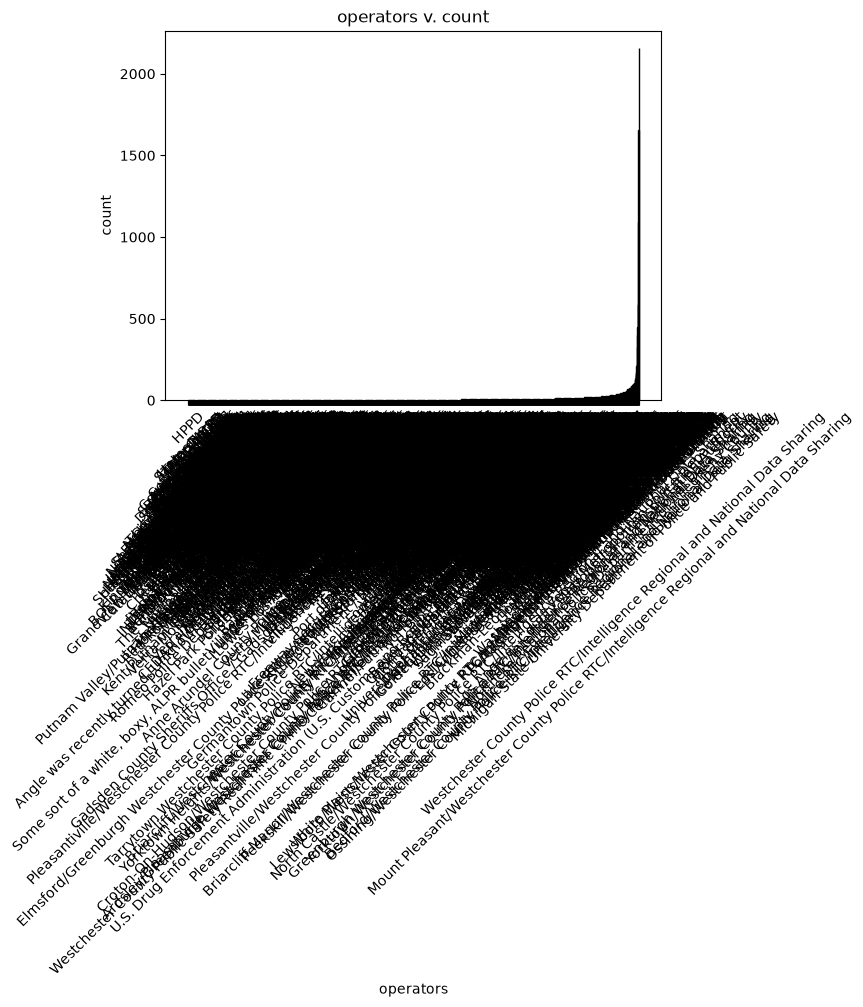

In [9]:
operator_col = first_four["operator"]
operator_col = operator_col.drop_nulls().value_counts().sort("count")
below_equal_to_ten = operator_col.filter(pl.col("count") <= 10)
# eleven_to_20 = operator_col.filter
# operator_col = operator_col.with_columns(pl.when(pl.col("count") <=10).then(pl.lit("Below 10")).otherwise(pl.col("operator")).alias("operator"))
# operator_col = operator_col.with_columns(pl.when(pl.col("count") <= 100).then(pl.lit("Below 50")).otherwise(pl.col("operator")).alias("operator"))
operator_col = operator_col.group_by("operator").agg(pl.sum("count")).sort("count")
print(below_equal_to_ten)
print(below_equal_to_ten.select(pl.sum("count")))
print(operator_col)
print(operator_col.select(pl.sum("count")))
print(operator_col.top_k(19, by="count"))
print(operator_col.top_k(19, by="count").select(pl.sum("count")))
plt.bar(operator_col["operator"].to_numpy(), operator_col["count"].to_numpy(), edgecolor="black")
# plt.hist(operator_col.to_numpy(), bins=100, edgecolor="black")
plt.xlabel("operators")
plt.ylabel("count")
plt.title("operators v. count")
plt.xticks(rotation=45)
plt.show()

The operators vs count bar chart is showing operators and their number of cameras deployed. There are 23,288 tagged cameras divided among 1,846 operators. The majority (79.43%) of operators are operating at most 10 cameras. Despite being 79.43% of operators this group only holds 19.75% of total tagged cameras. In comparison, the top 1% hold 38.51% of the tagged cameras due to some high-end outliers.

shape: (104, 2)
┌─────────────────────────────────┬───────┐
│ surveillanceZone                ┆ count │
│ ---                             ┆ ---   │
│ str                             ┆ u32   │
╞═════════════════════════════════╪═══════╡
│ east_oxford_street_(facing_wes… ┆ 1     │
│ westbound_traffic               ┆ 1     │
│ entrance;shop;traffic           ┆ 1     │
│ ualbany                         ┆ 1     │
│ Semmes Police Department Traff… ┆ 1     │
│ …                               ┆ …     │
│ school                          ┆ 6     │
│ parking_lot                     ┆ 6     │
│ entrance,_parking               ┆ 7     │
│ highway                         ┆ 7     │
│ street;traffic                  ┆ 8     │
└─────────────────────────────────┴───────┘
shape: (1, 1)
┌───────┐
│ count │
│ ---   │
│ u32   │
╞═══════╡
│ 178   │
└───────┘
shape: (122, 2)
┌─────────────────────────────────┬────────┐
│ surveillanceZone                ┆ count  │
│ ---                             ┆ ---    │
│

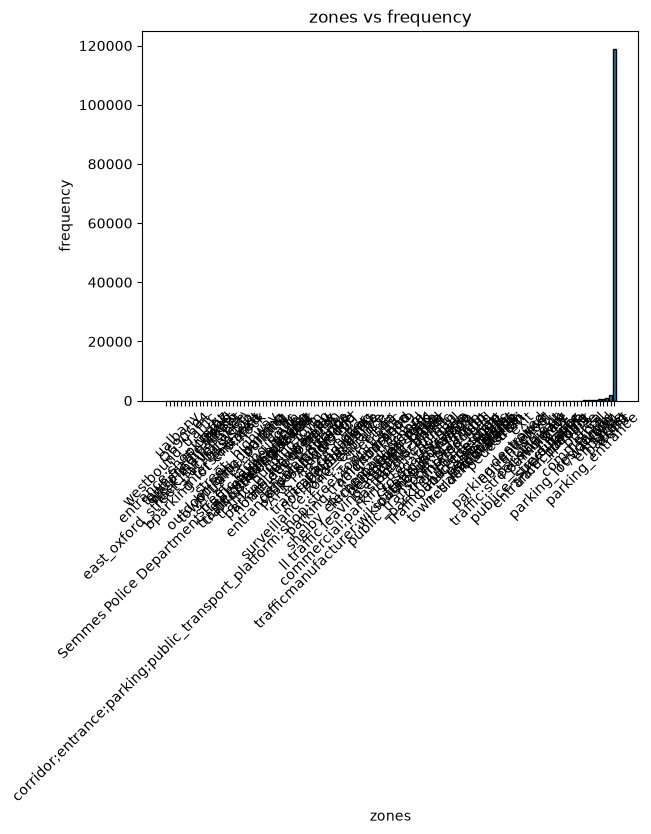

In [11]:
cat_col = second_four["surveillanceZone"]
cat_col = cat_col.drop_nulls().value_counts().sort("count")

below_equal_to_ten = cat_col.filter(pl.col("count") <= 10)
print(below_equal_to_ten)
print(below_equal_to_ten.select(pl.sum("count")))
print(cat_col)
print(cat_col.select(pl.sum("count")))
print(cat_col.filter(pl.col("surveillanceZone").str.contains("traffic")))
# print(cat_col.select(pl.sum("count")))
plt.bar(cat_col["surveillanceZone"].to_numpy(), cat_col["count"].to_numpy(), edgecolor="black")
# plt.hist(operator_col.to_numpy(), bins=100, edgecolor="black")
plt.xlabel("zones")
plt.ylabel("frequency")
plt.title("zones vs frequency")
plt.xticks(rotation=45)
plt.show()


The zones vs frequency bar chart displays the types of zones surveillance cameras a placed in and their frequency in the data set. In total there are 123,822 cameras with non-null surveillance divided among 122 distinct zones. The bar chart shows an extreme concentration at one surveillance zone. Of the 122 distince zones 96.09% of cameras fall under traffic surveillance showing a clear outlier. It is important to note that of the remaining 121 zones 34 contain the word "traffic".